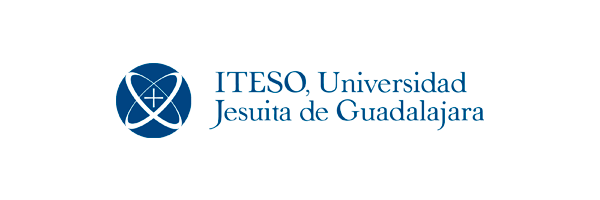

# Reporte de Prácticas de Redes Competitivas

**Integrantes:**

- Valeria Esmer Lobo

- Dayanni Godoy Rosales

- Estephany Lisset Herrera Placencia

- Maria Fernanda Vargas Vaca

**Fecha:** 6 de noviembre de 2026

**Institución:** Instituto Tecnológico y de Estudios Superiores de Occidente (ITESO)

**Materia:** Métodos de Inteligencia Artificial

## Índice

1. [Introducción y objetivos](#introduccion)
2. [Práctica 1: red competitiva programada desde cero](#practica1)
    - 2.1 [Definición del problema](#p1-definicion)
    - 2.2 [Descripción del algoritmo](#p1-algoritmo)
    - 2.3 [Implementación](#p1-implementacion)
    - 2.4 [Pruebas y resultados](#p1-pruebas)
3. [Práctica 2: red competitiva con MiniSom](#practica2)
4. [Conclusiones](#conclusiones)
    - 4.1 [Conclusiones personales](#conclusiones-personales)
    - 4.2 [Conclusiones generales](#conclusiones-generales)

<a id="introduccion"></a>

## 1. Introducción y objetivos

Las redes que usamos antes (ADALINE y perceptrón) aprenden con **aprendizaje supervisado**: cada dato trae la respuesta correcta y la red corrige sus pesos según el error. Una **red competitiva** aprende de forma **no supervisada**: los datos no traen etiqueta y la red tiene que descubrir sola qué grupos existen.

La idea es sencilla. Cada neurona tiene un vector de pesos que funciona como un "punto" en el mismo espacio que los datos. Cuando llega un dato, todas las neuronas **compiten** y gana la que está más cerca (menor distancia euclidiana). Solo la ganadora se actualiza y se acerca un poco al dato (*winner takes all*). Después de repetir esto muchas veces, cada neurona termina en el centro de un grupo de datos, y la red sirve para agrupar (*clustering*) y para decir a qué grupo pertenece un dato nuevo.

**Objetivo general:** implementar una red competitiva y usarla para encontrar los grupos que hay en un conjunto de datos sin etiquetas.

**Objetivos específicos**
- Programar desde cero la regla de aprendizaje competitivo y ver cómo se mueven los pesos durante el entrenamiento (Práctica 1).
- Usar la red entrenada para clasificar un dato nuevo.
- Revisar cómo cambian los resultados con el número de neuronas y la tasa de aprendizaje.
- Resolver un problema con más grupos usando la librería MiniSom (Práctica 2).

<a id="practica1"></a>

## 2. Práctica 1: red competitiva programada desde cero

<a id="p1-definicion"></a>

### 2.1 Definición del problema

El archivo `datos1.txt` contiene puntos en dos dimensiones $(x_1, x_2)$ **sin etiqueta de grupo**. En la gráfica se ve que forman **4 nubes** separadas. Se busca:

1. Entrenar una red competitiva de **4 neuronas** (una por grupo) para que cada neurona se ubique en el centro de un grupo.
2. Asignar cada punto al grupo de su neurona ganadora.
3. Usar la red entrenada para decir a qué grupo pertenece el dato nuevo $(0, 8)$.

<a id="p1-algoritmo"></a>

### 2.2 Descripción del algoritmo

1. **Inicialización:** se crean los pesos $W$ de las $n$ neuronas con valores aleatorios entre 0 y 1. Cada columna de $W$ es la posición de una neurona.
2. **Competencia:** para cada dato $x$ se calcula su distancia a cada neurona, $d_j = \lVert x - w_j \rVert^2$, y gana la más cercana: $g = \arg\min_j d_j$.
3. **Actualización (regla de Kohonen):** solo la ganadora se acerca al dato:
$$w_g \leftarrow w_g + \alpha\,(x - w_g)$$
   donde $\alpha$ es la tasa de aprendizaje. Con $\alpha = 0.1$, la neurona recorre el 10 % de la distancia que la separa del dato.
4. **Repetición:** se recorren todos los datos durante varias épocas, hasta que los pesos casi no se mueven.
5. **Clasificación:** cada dato, nuevo o de entrenamiento, pertenece al grupo de la neurona más cercana. La salida de la red es un vector *one-hot*: 1 en la neurona ganadora y 0 en las demás.

**Pseudocódigo**
```
INICIO
    Leer datos1.txt -> X (2 x m)
    W <- valores aleatorios en [0, 1)        // 2 x n, una columna por neurona
    PARA época = 1 HASTA 25 HACER
        PARA cada dato x en X HACER
            d_j <- || x - w_j ||^2  para j = 1..n
            g   <- índice del menor d_j       // neurona ganadora
            w_g <- w_g + alpha * (x - w_g)    // solo se mueve la ganadora
        FIN PARA
    FIN PARA
    Para cada dato: grupo <- neurona más cercana
    Para el dato nuevo (0, 8): salida one-hot de la neurona ganadora
FIN
```

<a id="p1-implementacion"></a>

### 2.3 Implementación

**a) Librerías y carga de datos**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Cargar los datos (cada columna es un punto y cada fila una variable)
data = np.loadtxt("datos1.txt", delimiter=",")
if data.shape[0] > data.shape[1]:      # Si viene con un punto por fila, se transpone
    data = data.T

print(f"Variables: {data.shape[0]} | Puntos: {data.shape[1]}")
print(f"Rango x1: [{data[0].min():.2f}, {data[0].max():.2f}] | Rango x2: [{data[1].min():.2f}, {data[1].max():.2f}]")

**b) Funciones de la red**

In [ ]:
def neurona_ganadora(x, W):
    # Distancia euclidiana al cuadrado entre el dato x y cada neurona (columna de W)
    distancias = np.sum((x.reshape(-1, 1) - W) ** 2, axis=0)
    return np.argmin(distancias), distancias


def entrenar_competitiva(data, nn, alpha, epocas, semilla=0):
    # Entrena la red: regresa pesos finales, pesos iniciales e historial por época
    rng = np.random.default_rng(semilla)          # Semilla fija para repetir resultados
    W = rng.random((data.shape[0], nn))           # Pesos aleatorios en [0, 1)
    W0 = W.copy()
    historial = [W.copy()]
    for _ in range(epocas):
        for k in range(data.shape[1]):
            x = data[:, k]
            g, _ = neurona_ganadora(x, W)
            W[:, g] = W[:, g] + alpha * (x - W[:, g])   # Solo se actualiza la ganadora
        historial.append(W.copy())
    return W, W0, np.array(historial)


def asignar_grupos(data, W):
    # Grupo de cada punto = neurona más cercana
    return np.array([neurona_ganadora(data[:, k], W)[0] for k in range(data.shape[1])])

**c) Entrenamiento** (4 neuronas, α = 0.1, 25 épocas)

In [ ]:
nn = 4          # Una neurona por grupo
alpha = 0.1     # Tasa de aprendizaje
epocas = 25

W, W0, historial = entrenar_competitiva(data, nn, alpha, epocas)
grupos = asignar_grupos(data, W)

print("Pesos iniciales (W0):")
print(np.round(W0, 4))
print("\nPesos finales (W) - cada columna es una neurona:")
print(np.round(W, 4))

<a id="p1-pruebas"></a>

### 2.4 Pruebas y resultados

**a) Movimiento de las neuronas y grupos encontrados**

In [ ]:
colores = ["tab:blue", "tab:orange", "tab:green", "tab:purple", "tab:brown", "tab:pink"]
fig, axs = plt.subplots(1, 2, figsize=(15, 6))

# Izquierda: recorrido de cada neurona desde su posición inicial
axs[0].plot(data[0], data[1], ".", color="lightgray", label="Datos")
for j in range(nn):
    axs[0].plot(historial[:, 0, j], historial[:, 1, j], "-o", ms=3, color=colores[j])
    axs[0].text(W[0, j] + 0.3, W[1, j] + 0.3, str(j + 1), fontsize=14, fontweight="bold", color=colores[j])
axs[0].plot(W0[0], W0[1], "ks", ms=6, label="Pesos iniciales")
axs[0].plot(W[0], W[1], "r*", ms=16, label="Pesos finales")
axs[0].set(title="Recorrido de las neuronas durante el entrenamiento", xlabel="x1", ylabel="x2")
axs[0].legend(); axs[0].grid(alpha=0.3)

# Derecha: datos coloreados según su neurona ganadora
for j in range(nn):
    axs[1].plot(data[0, grupos == j], data[1, grupos == j], ".", color=colores[j], label=f"Grupo {j + 1}")
axs[1].plot(W[0], W[1], "r*", ms=16, label="Neuronas")
axs[1].set(title="Agrupación final - Red competitiva", xlabel="x1", ylabel="x2")
axs[1].legend(); axs[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**b) Convergencia:** cuánto se mueven los pesos en cada época

In [ ]:
movimiento = np.linalg.norm(np.diff(historial, axis=0), axis=1)   # Desplazamiento de cada neurona por época
movimiento = np.maximum(movimiento, 1e-16)                         # Evita log(0) cuando ya no se mueven

plt.figure(figsize=(9, 4.5))
for j in range(nn):
    plt.semilogy(range(1, epocas + 1), movimiento[:, j], "-o", ms=4, color=colores[j], label=f"Neurona {j + 1}")
plt.xlabel("Época"); plt.ylabel("Desplazamiento de los pesos (escala log)")
plt.title("Convergencia de la red competitiva")
plt.legend(); plt.grid(True, which="both", alpha=0.3)
plt.show()

# Resumen por grupo
resumen = pd.DataFrame({
    "Neurona": range(1, nn + 1),
    "Peso final x1": W[0].round(3),
    "Peso final x2": W[1].round(3),
    "Puntos asignados": [int((grupos == j).sum()) for j in range(nn)],
    "Centro real x1": [data[0, grupos == j].mean().round(3) for j in range(nn)],
    "Centro real x2": [data[1, grupos == j].mean().round(3) for j in range(nn)]})
resumen

**c) Clasificación del dato nuevo $(0, 8)$**

In [ ]:
test = np.array([0, 8])
idx, distancias_test = neurona_ganadora(test, W)

# Vector de salida one-hot: 1 en la neurona ganadora
salida = np.zeros((nn, 1))
salida[idx, 0] = 1

print(f"Distancias del dato {test} a cada neurona: {np.round(distancias_test, 4)}")
print(f"Neurona ganadora: {idx + 1}")
print("Salida de la red (one-hot):")
print(salida)

**d) Pruebas con distinto número de neuronas y tasa de aprendizaje**

Se repite el entrenamiento (25 épocas, misma semilla) cambiando $n$ y $\alpha$. Para cada caso se reportan las **neuronas muertas** (las que nunca ganan y se quedan sin datos) y el **error de cuantización**, que es la distancia promedio de cada punto a su neurona; entre menor sea, mejor representan las neuronas a los datos.

In [ ]:
def evaluar_caso(nn_c, alpha_c, epocas_c=25):
    W_c, _, _ = entrenar_competitiva(data, nn_c, alpha_c, epocas_c)
    g_c = asignar_grupos(data, W_c)
    error = np.mean(np.linalg.norm(data - W_c[:, g_c], axis=0))
    return {"Neuronas": nn_c, "alpha": alpha_c,
            "Neuronas muertas": int(sum((g_c == j).sum() == 0 for j in range(nn_c))),
            "Puntos por neurona": [int((g_c == j).sum()) for j in range(nn_c)],
            "Error de cuantización": round(error, 4)}

casos = [(4, 0.01), (4, 0.1), (4, 0.5), (3, 0.1), (5, 0.1), (6, 0.1)]
tabla_casos = pd.DataFrame([evaluar_caso(n_c, a_c) for n_c, a_c in casos])
tabla_casos.index = [f"Caso {i}" for i in range(1, len(casos) + 1)]
tabla_casos

In [ ]:
# Resumen de resultados en palabras
print("RESUMEN DE LA PRÁCTICA 1")
dist_centro = np.linalg.norm(W - np.vstack((resumen["Centro real x1"], resumen["Centro real x2"])), axis=0)
print(f"- Cada neurona quedó a {dist_centro.min():.3f}-{dist_centro.max():.3f} unidades del centro de su grupo.")
print(f"- Puntos por grupo: {resumen['Puntos asignados'].tolist()}.")
mov_max = movimiento.max(axis=1)
estable = np.argmax(mov_max < 1e-3) + 1 if (mov_max < 1e-3).any() else None
print(f"- Los pesos se movieron menos de 0.001 a partir de la época {estable}." if estable
      else "- Los pesos todavía se movían al terminar las épocas.")
print(f"- El dato nuevo {test} quedó en el grupo de la neurona {idx + 1}, cuyo peso es ({W[0, idx]:.2f}, {W[1, idx]:.2f}).")
mejor = tabla_casos.loc[tabla_casos["Neuronas muertas"] == 0, "Error de cuantización"].idxmin()
print(f"- En la tabla de casos, el menor error sin neuronas muertas es el {mejor} "
      f"({tabla_casos.loc[mejor, 'Neuronas']} neuronas, alpha = {tabla_casos.loc[mejor, 'alpha']}).")
muertas = tabla_casos[tabla_casos["Neuronas muertas"] > 0]
if len(muertas):
    print(f"- Casos con neuronas muertas: {', '.join(muertas.index)}.")

**Análisis**
- **Agrupación:** con 4 neuronas y α = 0.1, cada neurona termina prácticamente en el centro de una de las 4 nubes. Su peso final coincide con el promedio de los puntos de su grupo (tabla del inciso b), y el resultado es igual al que darían los centroides de los grupos, aunque la red nunca vio etiquetas.
- **Recorrido:** todos los pesos empiezan juntos cerca del origen porque se inician entre 0 y 1. Las neuronas que ganan los primeros datos se mueven primero. Una neurona puede pasar por un grupo antes de llegar al suyo si otra neurona termina "ganándole" ese grupo.
- **Convergencia:** el desplazamiento cae muy rápido. Después de pocas épocas los pesos casi no cambian, así que 25 épocas son más que suficientes.
- **Dato nuevo (0, 8):** la red activa una sola neurona (salida one-hot), la del grupo de arriba a la izquierda, que es el más cercano a ese punto.
- **Número de neuronas:** con menos neuronas que grupos (3), una neurona tiene que cubrir dos nubes y queda en medio de ellas, por eso el error sube. Con más neuronas que grupos, las sobrantes nunca ganan (**neuronas muertas**) o parten un grupo en dos. Hay que elegir tantas neuronas como grupos.
- **Tasa de aprendizaje:** si α es muy chica, las neuronas avanzan tan poco que una puede quedarse cerca del origen y nunca ganar. Si es muy grande, la ganadora "brinca" hacia cada dato y puede quedarse con datos de dos grupos. α = 0.1 da un buen equilibrio.
- **Inicialización:** las neuronas muertas aparecen porque los pesos iniciales están lejos de los datos. Iniciarlos en el centroide de los datos (con una pequeña perturbación) o en puntos tomados de los mismos datos evita este problema.

<a id="practica2"></a>

## 3. Práctica 2: red competitiva con MiniSom

In [27]:
from minisom import MiniSom

In [31]:
data = np.loadtxt("datos2.txt", delimiter = ",")

print(f"Dimensiones de los daots : {data.shape}")




Dimensiones de los daots : (2, 1000)


In [33]:
nn = 6
red = MiniSom(x = nn, y=1, input_len=data.shape[0], sigma = 0.01, learning_rate = 0.5)

epocas = 100
iteraciones_totales = epocas * data.shape[1]

red.random_weights_init(data.T)
red.train_random(data.T, num_iteration = iteraciones_totales)

Wf = red.get_weights().reshape(nn, data.shape[0])

print("\nPesos Finales (Wf):")
print(Wf)


Pesos Finales (Wf):
[[ 9.28700393e-01  6.60411768e-02]
 [ 1.22189157e+00  1.08901425e+00]
 [-7.20653632e-02 -1.99772183e-01]
 [ 5.20827129e-01  9.78413822e-01]
 [ 9.33674687e-04  2.92970987e-01]
 [-1.86768991e-01  1.09470749e+00]]



Grupos únicos identificados por la red: [0 1 2 3 4 5]

El dato nuevo [1.  1.5] fue clasificado en el grupo: 1


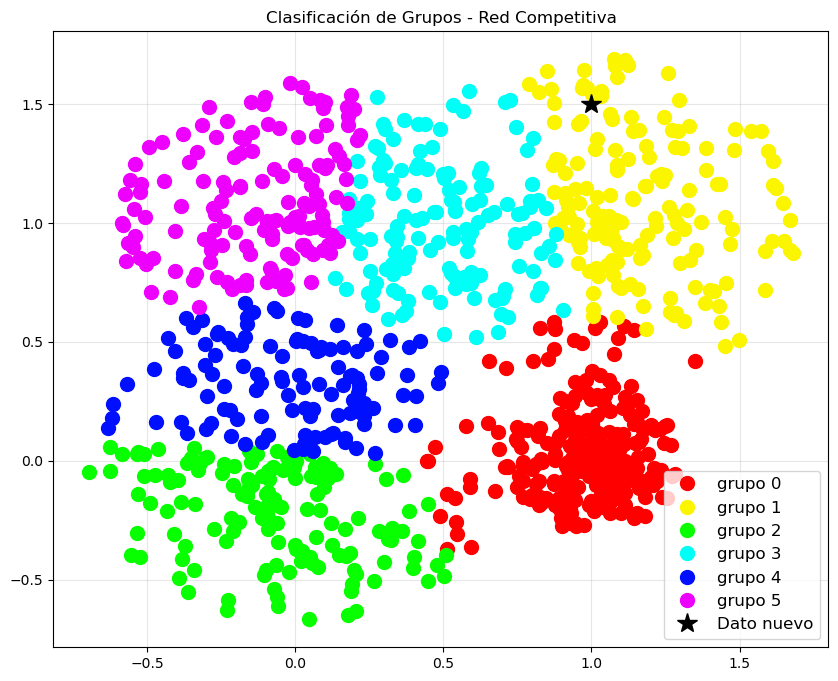

In [38]:
# Simulación (Categorizar todos los datos de entrenamiento)
Y = np.array([red.winner(muestra)[0] for muestra in data.T])

grupos = np.unique(Y)
print(f"\nGrupos únicos identificados por la red: {grupos}")

# Reporte de datos
data_reporte = np.vstack((data,Y))

v = np.array([1.0,1.5])
t = red.winner(v)[0]

v_reporte = np.append(v,t)

print(f"\nEl dato nuevo {v} fue clasificado en el grupo: {t}")

# Gráfica Unificada
plt.figure(figsize = (10,8))

cmap = plt.get_cmap("hsv")
colores = [cmap(i / len(grupos)) for i in range(len(grupos))]

for k, g in enumerate(grupos):
    temp = data[:, Y ==g]

    plt.plot(temp[0,:], temp[1,:], "o", color = colores[k],
             linewidth = 3, markersize = 10, label = f"grupo {g}")

plt.plot(v[0], v[1], "k*", linewidth = 3, markersize = 15, label = "Dato nuevo")

plt.title("Clasificación de Grupos - Red Competitiva")
plt.legend(fontsize = 12, loc = "best")
plt.grid(True, alpha = 0.3)
plt.show()

##  Practica 3 Red Neuronal Competitiva para el agrupamiento de activos de la BMV

### Introduccion 
Una red neuronal competitiva aprende sin supervisión: las neuronas "compiten" por cada dato y solo la que más se le parece (la ganadora) ajusta sus pesos hacia él. Al final, cada neurona queda como el prototipo (centroide) de un grupo de datos parecidos.

Aquí la usé para agrupar 35 activos de la BMV según cómo se comportan en el tiempo. Como sus precios están en escalas muy distintas, primero los normalicé con Z-score para comparar la forma de cada serie y no su tamaño.

Objetivo: separar los 35 activos en 4 grupos de comportamiento parecido, usando una red competitiva con MiniSom, y analizar qué tiene cada grupo.

Agrupamiento Competitivo de los 35 Activos de la BMV:

Activo BMV_01: Pertenece a la Neurona Ganadora 1
Activo BMV_02: Pertenece a la Neurona Ganadora 1
Activo BMV_03: Pertenece a la Neurona Ganadora 1
Activo BMV_04: Pertenece a la Neurona Ganadora 1
Activo BMV_05: Pertenece a la Neurona Ganadora 3
Activo BMV_06: Pertenece a la Neurona Ganadora 1
Activo BMV_07: Pertenece a la Neurona Ganadora 3
Activo BMV_08: Pertenece a la Neurona Ganadora 3
Activo BMV_09: Pertenece a la Neurona Ganadora 3
Activo BMV_10: Pertenece a la Neurona Ganadora 1
Activo BMV_11: Pertenece a la Neurona Ganadora 3
Activo BMV_12: Pertenece a la Neurona Ganadora 4
Activo BMV_13: Pertenece a la Neurona Ganadora 1
Activo BMV_14: Pertenece a la Neurona Ganadora 4
Activo BMV_15: Pertenece a la Neurona Ganadora 2
Activo BMV_16: Pertenece a la Neurona Ganadora 1
Activo BMV_17: Pertenece a la Neurona Ganadora 1
Activo BMV_18: Pertenece a la Neurona Ganadora 3
Activo BMV_19: Pertenece a la Neurona Ganadora 1
Activo BMV_20:

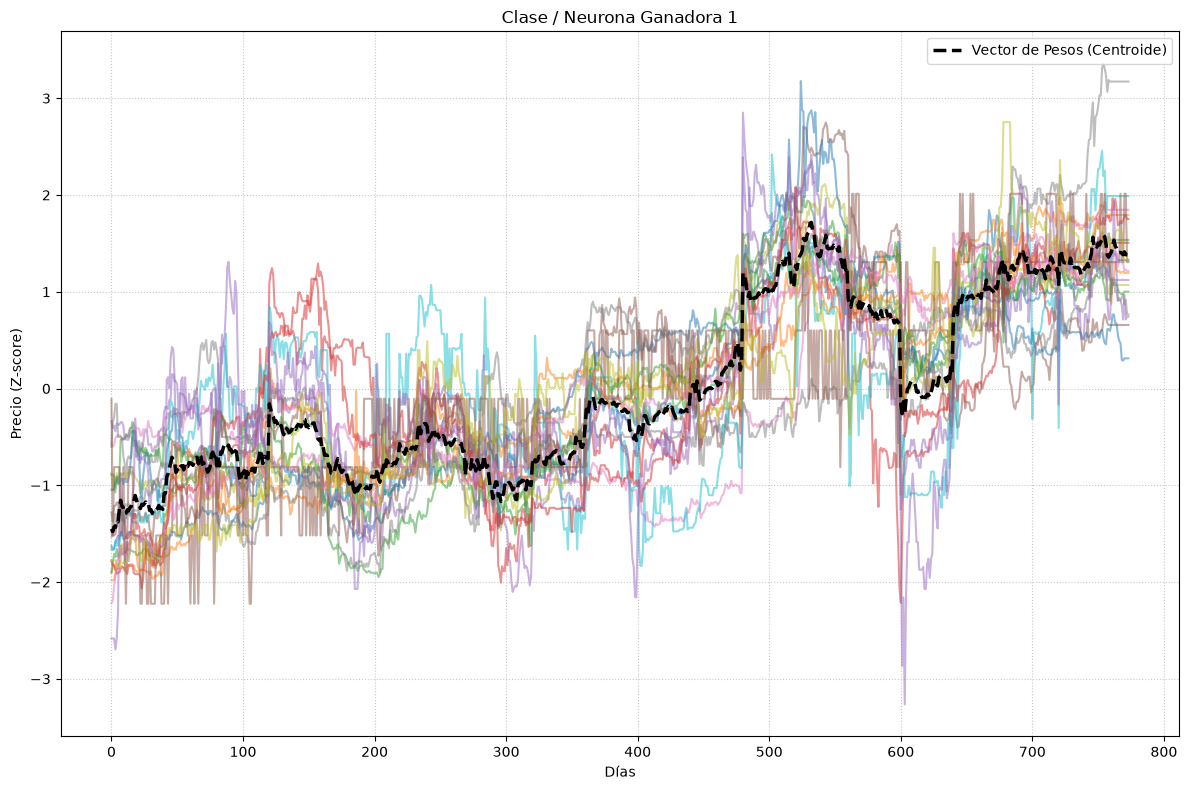

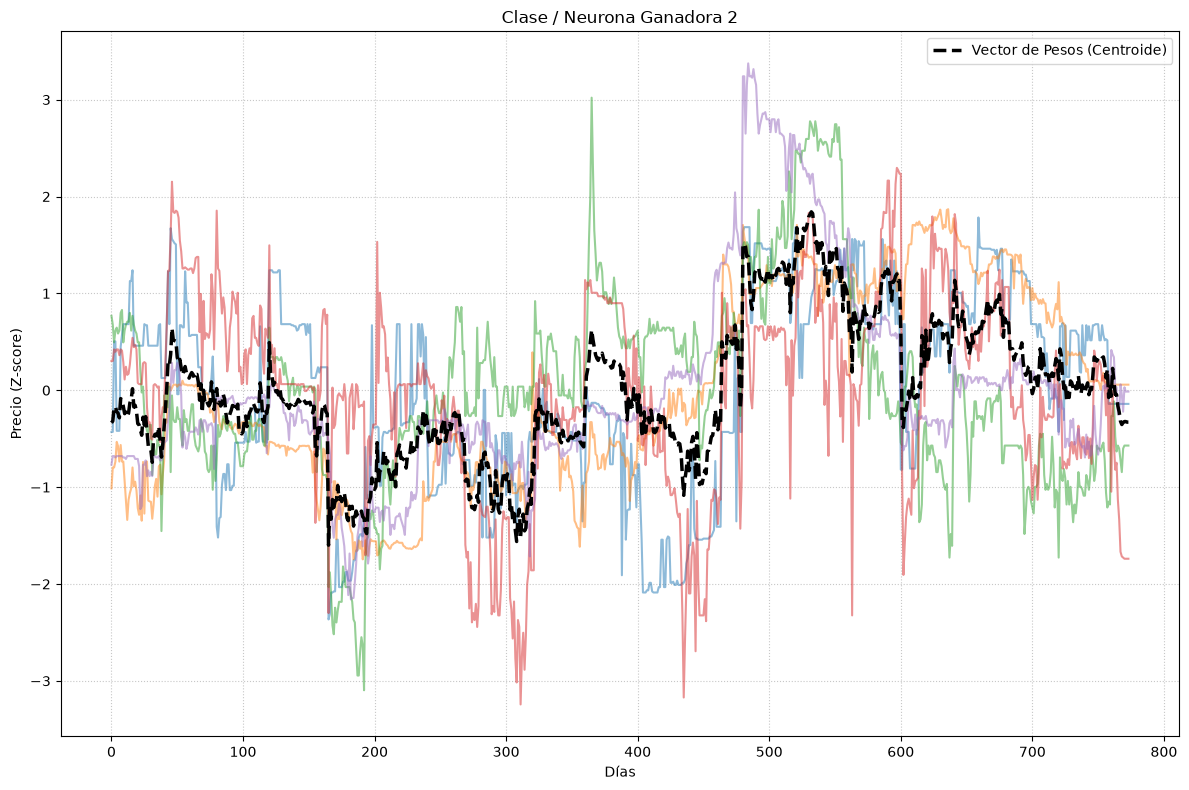

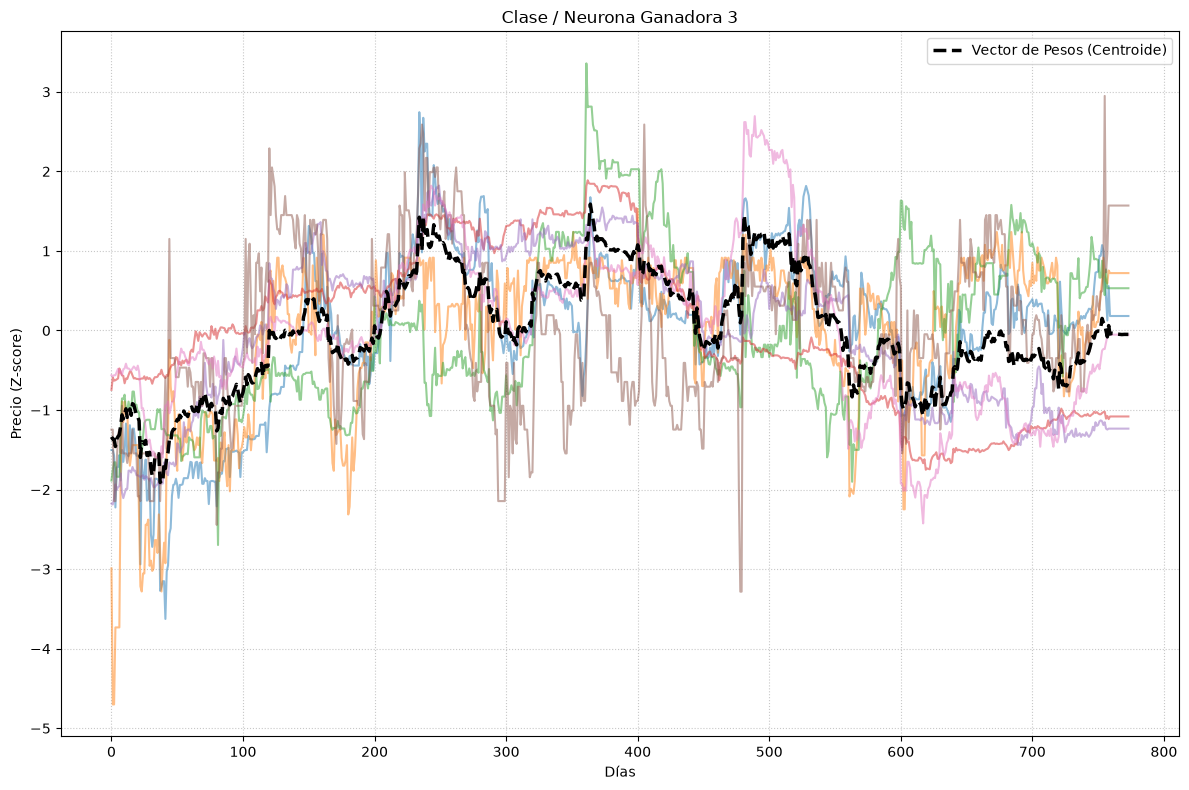

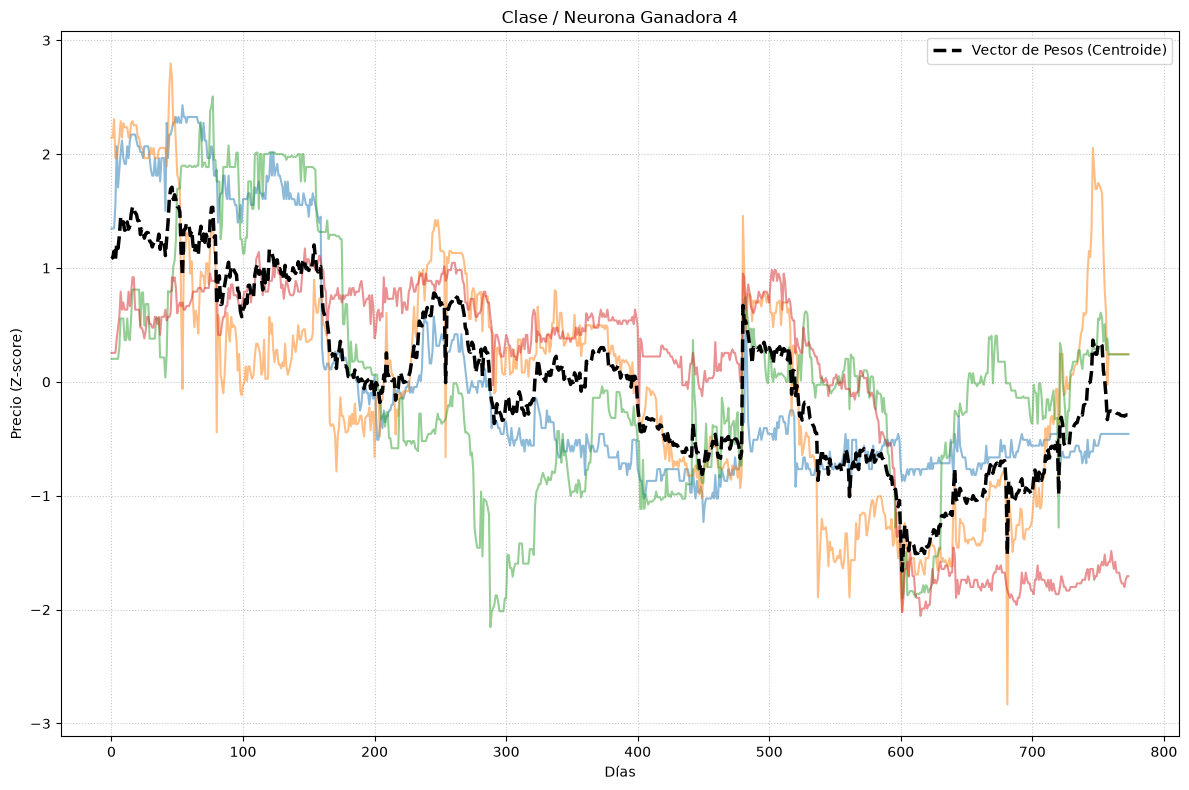

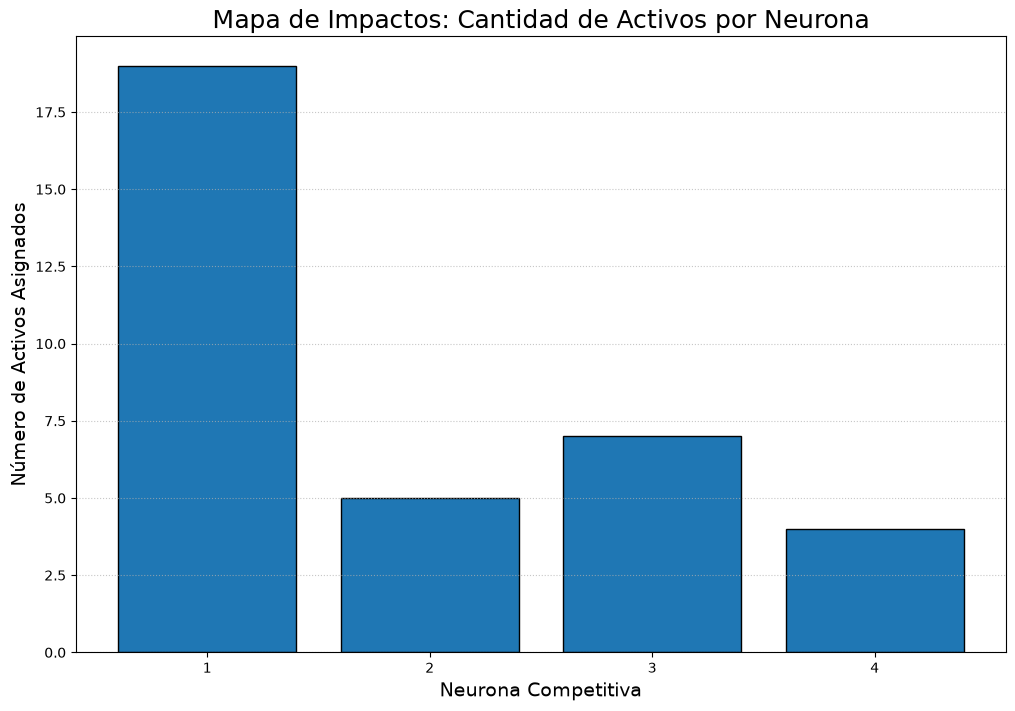

In [2]:
import numpy as np
import pandas as pd
from scipy.stats import zscore
from minisom import MiniSom
import matplotlib.pyplot as plt

# 1. Cargar los datos
df = pd.read_csv('Datos_BMV.csv', header=None)
data = df.values 

# Normalizar los datos por columna usando Z-score
data_norm = zscore(data, axis=0)

# 2. Preparar los datos para la red
# Cada fila representa un activo y cada columna un día
X_train = data_norm.T  
num_activos, num_dias = X_train.shape

# 3. Configurar la red neuronal
# Se utilizan 4 neuronas competitivas
num_neuronas = 4  
som = MiniSom(x=num_neuronas, y=1, input_len=num_dias, sigma=1.0, learning_rate=0.5, random_seed=42)

# Inicializar los pesos de las neuronas
som.random_weights_init(X_train)

# 4. Entrenar la red neuronal
num_iteraciones = 1000  
som.train_random(data=X_train, num_iteration=num_iteraciones)

# 5. Clasificar los activos
print("Agrupamiento Competitivo de los 35 Activos de la BMV:\n")
etiquetas_clases = []

# Identificar la neurona ganadora de cada activo
for i, x in enumerate(X_train):
    neurona_ganadora = som.winner(x)[0] 
    clase_asignada = neurona_ganadora + 1 
    etiquetas_clases.append(clase_asignada)
    print(f"Activo BMV_{i+1:02d}: Pertenece a la Neurona Ganadora {clase_asignada}")

# 6. Gráfica 1: Comportamiento de los activos por grupo

# Obtener los pesos finales de las neuronas
pesos_red = som.get_weights()[:, 0, :]

# Crear una gráfica para cada neurona
for i in range(num_neuronas):
    plt.figure(figsize=(12,8))
    plt.title(f'Clase / Neurona Ganadora {i + 1}',fontsize=12)

    # Seleccionar los activos que pertenecen a cada grupo
    activos_clase = [idx for idx, clase in enumerate(etiquetas_clases) if clase == i + 1]

    # Graficar los activos del grupo
    for idx in activos_clase:
        plt.plot(X_train[idx], alpha=0.5)

    # Agregar los pesos de la neurona como referencia
    plt.plot(pesos_red[i], color='black', linewidth=2.5, linestyle='--', label='Vector de Pesos (Centroide)')

    plt.ylabel('Precio (Z-score)')
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.legend(loc='upper right')
    plt.xlabel('Días')
    plt.tight_layout()
    plt.show()

# 7. Gráfica 2: Cantidad de activos por neurona

# Contar cuántos activos quedaron en cada grupo
frecuencias = [etiquetas_clases.count(i) for i in range(1, num_neuronas + 1)]

# Graficar la cantidad de activos por neurona
plt.figure(figsize=(12, 8))
plt.bar(range(1, num_neuronas + 1), frecuencias, color='#1f77b4', edgecolor='black')
plt.title('Mapa de Impactos: Cantidad de Activos por Neurona', fontsize=18)
plt.xlabel('Neurona Competitiva', fontsize=14)
plt.ylabel('Número de Activos Asignados', fontsize=14)
plt.xticks(range(1, num_neuronas + 1))
plt.grid(axis='y', linestyle=':', alpha=0.7)
plt.show()

## Resultados 
Clasificación: Los 35 activos se distribuyeron en 4 neuronas: 19 en la neurona 1, 5 en la 2, 7 en la 3 y 4 en la 4.

Gráficas por clase: Las líneas de colores representan los activos y la línea negra punteada el centroide de cada grupo.
- Neurona 1: Comportamiento principalmente alcista y el grupo más compacto.
- Neurona 2: Comportamiento lateral, con bastante volatilidad.
- Neurona 3: Presenta una tendencia alcista inicial y después se estabiliza.
- Neurona 4: Comportamiento bajista, contrario a la neurona 1.
Mapa de impactos: La neurona 1 concentra más de la mitad de los activos (19), seguida de la 3 (7), la 2 (5) y la 4 (4). Esto muestra que el comportamiento más frecuente fue el alcista, mientras que el bajista fue el menos común.

<a id="conclusiones"></a>

## 4. Conclusiones

<a id="conclusiones-personales"></a>

### 4.1 Conclusiones personales

**Dayanni**

Esta práctica me ayudó a ver la diferencia entre las redes que usamos antes y una red competitiva. Aquí no le dimos a la red ninguna respuesta correcta y aun así encontró sola los cuatro grupos: cada neurona terminó en el centro de una nube de puntos. Me llamó la atención lo sencilla que es la regla, porque solo se mueve la neurona más cercana, y aun así funciona muy bien. También aprendí que el resultado depende mucho de cómo se configure la red: si ponemos menos neuronas que grupos, una neurona tiene que cubrir dos nubes, y si ponemos de más o elegimos mal la tasa de aprendizaje, aparecen neuronas que nunca ganan y no sirven para nada. Por eso es importante conocer primero los datos y elegir bien el número de neuronas y la forma de iniciar los pesos.

**Esmer**
 

Las redes competitivas me parecieron una forma muy intuitiva de aprendizaje no supervisado: la idea de que las neuronas "compiten" y la ganadora se vuelve el representante de un grupo es sencilla, pero funciona bien para encontrar patrones que uno no ve a simple vista. Me gustó que no necesitan etiquetas y que cada neurona se puede interpretar directamente como el prototipo de su clase. Aprendí que su resultado depende mucho de cómo se preparan los datos y de los parámetros que uno elige, como el número de neuronas, la tasa de aprendizaje y la inicialización, así que no hay una única respuesta correcta y hay que analizar los grupos con criterio. Creo que son útiles en muchos problemas además de las finanzas, como segmentar clientes, comprimir información o clasificar señales e imágenes cuando no se tienen datos etiquetados.

<a id="conclusiones-generales"></a>

### 4.2 Conclusiones generales